# 4. Noisy simulation of the randomized-basis implementation (Appendix A: Tables 2, 3 and Fig. 5)

The joint POVMs of Propositions 2 and 4 are implemented as randomized single-qubit basis measurements
(Remark on the randomized implementation): each copy draws a measurement axis $\boldsymbol n$, applies $U_{\boldsymbol n}$ with
$U_{\boldsymbol n}^\dagger Z U_{\boldsymbol n} = \boldsymbol n\cdot\boldsymbol\sigma$ and measures $Z$. This notebook runs four simulations
with the `jointpovm` package:

| run | executor | used for |
|---|---|---|
| `fake_backend_q72` | `FakeKingston` noise model (calibration snapshot of `ibm_kingston`, 15 April 2026), qubit 72 | Table 2, Fig. 5, X/Y/Z numbers |
| `fake_backend` | same, qubit with the smallest readout error (qubit 50) | X/Y/Z numbers, effect of calibration |
| `simulator_readout_p01_0.0085_p10_0.098` | Aer, no gate noise, asymmetric readout | Table 3 |
| `simulator_exact` | Aer, noiseless | shared multinomial axis counts |

For every angle $\theta\in\{0^\circ,20^\circ,45^\circ,90^\circ\}$: the pair POVM on the six cardinal states (marginal tomography)
and on $R_y(35^\circ)|0\rangle$, the grouped pair measurement, and for $X,Y,Z$ the cube-diagonal POVM and sharp
grouped measurements on $R_z(30^\circ)R_y(55^\circ)|0\rangle$. $N = 10^4$ copies per configuration, multinomial axis counts,
$10^4$ calibration shots per basis state, 95% bootstrap intervals with 2000 resamples.

**No quantum hardware is used.** The fake backend is a local Aer simulation with a noise model built from a stored
calibration snapshot; its results depend on the pinned `qiskit-ibm-runtime==0.52.1`.

Outputs: `results/*.json` (+ per-shot data `results/raw_*.npz`), `results/sdp_eta.json`,
`results/table2_noisysim.tex`, `results/table3_asym.tex`, `figures/fig_noisy_sim.pdf`.

**Run time:** a few minutes. Set `RECOMPUTE = False` to analyse saved results only.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS, FIGURES, REFERENCE = ROOT / "results", ROOT / "figures", ROOT / "reference"
RESULTS.mkdir(exist_ok=True); FIGURES.mkdir(exist_ok=True)

import time
import matplotlib.pyplot as plt
from qiskit_ibm_runtime import fake_provider

from jointpovm import schemes as S
from jointpovm.axes import PAULIS, dot_sigma, pair_vectors
from jointpovm.cli import job_summary
from jointpovm.execute import AerExecutor, BackendExecutor, readout_noise_model
from jointpovm.experiment import DEFAULT_THETAS, analyse, build_plan, package_versions, run_plan, save
from jointpovm.figures import noisy_sim_figure, setup
from jointpovm.sdp import eta_star
from jointpovm.states import CARDINAL, bloch
from copycost.style import find_latex
import warnings
warnings.filterwarnings("ignore", message="Solution may be inaccurate")   # Clarabel at 1e-10 tolerance
warnings.filterwarnings("ignore", message="All-NaN slice")               # quantities undefined at mu = 0

RECOMPUTE = True
N, BOOT, ALLOC_SEED, SIM_SEED, CHUNK = 10_000, 2000, 1234, 4321, 500   # settings of the paper runs
THETAS = ["0", "20", "45", "90"]

## SDP thresholds for panel (a) of Fig. 5

Qubit pair at the angles of the figure (including $45^\circ$) and the $X,Y,Z$ block.

In [2]:
sdp = {"pair": {"theta_deg": [], "eta_sdp": [], "eta_closed_form": []}, "versions": package_versions()}
for th in [0, 10, 20, 30, 40, 45, 50, 60, 70, 80, 90]:
    a, b = pair_vectors(th)
    sdp["pair"]["theta_deg"].append(th)
    sdp["pair"]["eta_sdp"].append(eta_star([dot_sigma(a), dot_sigma(b)]))
    sdp["pair"]["eta_closed_form"].append(S.pair_eta(th))
sdp["xyz"] = {"eta_sdp": eta_star(list(PAULIS)), "eta_closed_form": 1 / np.sqrt(3)}
(RESULTS / "sdp_eta.json").write_text(json.dumps(sdp, indent=1))
pd.DataFrame(sdp["pair"]).assign(diff=lambda d: d.eta_sdp - d.eta_closed_form)

,theta_deg,eta_sdp,eta_closed_form,diff
0,0,1.000000,1.000000,-1.977196e-12
1,10,0.923062,0.923062,3.978817e-12
2,20,0.863218,0.863218,-3.878020e-11
3,30,0.816497,0.816497,-1.832356e-11
4,40,0.780206,0.780206,1.103895e-12
5,45,0.765367,0.765367,-3.243272e-11
6,50,0.752487,0.752487,-1.291889e-11
7,60,0.732051,0.732051,-6.508261e-11
8,70,0.718015,0.718015,-1.134648e-13
9,80,0.709808,0.709808,-1.273974e-10


## Simulation runs

`run` executes the full plan (calibration, pair and $X,Y,Z$ configurations), analyses it and saves the JSON
with metadata (package versions, seeds, transpiled depth, backend calibration values).
All runs share the allocation seed, so they use the same multinomial axis counts.

In [3]:
def run(name, executor, **meta_extra):
    plan = build_plan(thetas=DEFAULT_THETAS, n=N)
    t0 = time.time()
    out = run_plan(plan, executor, seed=ALLOC_SEED)
    res = analyse(plan, out["raw"], n_boot=BOOT)
    meta = dict(executor.meta, sim_seed=SIM_SEED, **meta_extra, **out["meta"])
    args = {"thetas": list(DEFAULT_THETAS), "n": N, "n_cal": None, "seed": ALLOC_SEED, "sim_seed": SIM_SEED,
            "boot": BOOT, "chunk": CHUNK}
    path = save(RESULTS / f"{name}.json", {"run": meta, "args": args, **res}, raw=out["raw"])
    print(f"{name}: {meta['n_circuits']} circuits, {meta['n_shots']:,} shots, "
          f"p01={res['calibration']['p01']:.4f} p10={res['calibration']['p10']:.4f}  ({time.time() - t0:.0f} s)")
    return path


def fake_run(name, qubit):
    ex = BackendExecutor(fake_provider.FakeKingston(), qubit=qubit, seed=SIM_SEED, chunk=CHUNK)
    summ = job_summary(build_plan(thetas=DEFAULT_THETAS, n=N), ex, ALLOC_SEED)
    return run(name, ex, dry_run_summary=summ)


if RECOMPUTE:
    fake_run("fake_backend_q72", qubit=72)
    fake_run("fake_backend", qubit=None)            # None = qubit with the smallest readout error
    run("simulator_readout_p01_0.0085_p10_0.098",
        AerExecutor(seed=SIM_SEED, noise_model=readout_noise_model(0.0085, 0.098)), readout_p01=0.0085, readout_p10=0.098)
    run("simulator_exact", AerExecutor(seed=SIM_SEED), readout_p01=None, readout_p10=None)

load = lambda n: json.loads((RESULTS / f"{n}.json").read_text())
Q72, Q50 = load("fake_backend_q72"), load("fake_backend")
ASY, EXA = load("simulator_readout_p01_0.0085_p10_0.098"), load("simulator_exact")

fake_backend_q72: 88 circuits, 420,000 shots, p01=0.0519 p10=0.0544  (5 s)


fake_backend: 88 circuits, 420,000 shots, p01=0.0018 p10=0.0023  (5 s)


simulator_readout_p01_0.0085_p10_0.098: 88 circuits, 420,000 shots, p01=0.0072 p10=0.0995  (1 s)


simulator_exact: 88 circuits, 420,000 shots, p01=0.0000 p10=0.0000  (1 s)


## Readout calibration

$p_{01} = P(\text{read }1\mid 0)$ and $p_{10} = P(\text{read }0\mid 1)$ from $10^4$ preparations of each basis state.
For the fake backend the snapshot reports an asymmetric readout error, but Aer's `NoiseModel.from_backend`
uses the symmetric `readout_error` entry in both directions; the asymmetric effect is therefore studied with the
explicit readout model of the third run.

In [4]:
rows = []
for R, n in ((Q72, "fake, qubit 72"), (Q50, "fake, qubit 50"), (ASY, "asymmetric readout")):
    c, r = R["calibration"], R["run"]
    rows.append({"run": n, "qubit": r.get("qubit"),
                 "p01": c["p01"], "p01 95% CI": np.round(c["p01_ci95"], 4).tolist(),
                 "p10": c["p10"], "p10 95% CI": np.round(c["p10_ci95"], 4).tolist(),
                 "1 - p01 - p10": 1 - c["p01"] - c["p10"],
                 "reported P(1|0)": r.get("reported_prob_meas1_prep0"), "reported P(0|1)": r.get("reported_prob_meas0_prep1"),
                 "reported readout_error": r.get("reported_readout_error")})
pd.DataFrame(rows).style.format(precision=4, na_rep="-")

,run,qubit,p01,p01 95% CI,p10,p10 95% CI,1 - p01 - p10,reported P(1|0),reported P(0|1),reported readout_error
0,"fake, qubit 72",72.0000,0.0519,"[0.0475, 0.0564]",0.0544,"[0.05, 0.059]",0.8937,0.0085,0.0981,0.0533
1,"fake, qubit 50",50.0000,0.0018,"[0.001, 0.0027]",0.0023,"[0.0014, 0.0033]",0.9959,0.0010,0.0027,0.0018
2,asymmetric readout,-,0.0072,"[0.0056, 0.0089]",0.0995,"[0.0938, 0.1056]",0.8933,-,-,-


## Table 2: tomographic sharpness of the pair POVM (qubit 72)

Each marginal effect is fitted as $\tfrac12(\alpha I + \boldsymbol v\cdot\boldsymbol\sigma)$ from the six cardinal states,
$v_i = \tfrac12(E[j\mid+\boldsymbol e_i] - E[j\mid-\boldsymbol e_i])$. Raw $\|\boldsymbol v\|$ is compared with
$\eta(1-p_{01}-p_{10})$ and calibrated $\|\boldsymbol v\|$ with $\eta$.

In [5]:
def ci(e, k=None, nd=3):
    v = e["value"] if k is None else e["value"][k]
    lo, hi = (e["ci95"] if k is None else (e["ci95"][0][k], e["ci95"][1][k]))
    return f"\\vci{{{v:.{nd}f}}}{{{lo:.{nd}f},{hi:.{nd}f}}}"

def plain(s):     # \vci{v}{lo,hi} -> "v [lo, hi]" for display
    v, rest = s[5:].split("}{"); return f"{v} [{rest[:-1].replace(',', ', ')}]"

gain = 1 - Q72["calibration"]["p01"] - Q72["calibration"]["p10"]
tex2, rows = [], []
for th in THETAS:
    d = Q72["derived"]["tomography"][th]
    eta = np.linalg.norm(d["A|raw"]["target"])
    cells = [ci(d["A|raw"]["sharpness"]), ci(d["A'|raw"]["sharpness"]),
             ci(d["A|cal_asym"]["sharpness"]), ci(d["A'|cal_asym"]["sharpness"])]
    tex2.append(f"${th}^\\circ$ & ${eta:.4f}$ & ${eta * gain:.4f}$ & " + " & ".join(cells) + " \\\\")
    rows.append([th, f"{eta:.4f}", f"{eta * gain:.4f}"] + [plain(c) for c in cells])
(RESULTS / "table2_noisysim.tex").write_text("\n".join(tex2) + "\n")
display(pd.DataFrame(rows, columns=["theta", "eta", "eta(1-p01-p10)", "raw A", "raw A'", "calibrated A", "calibrated A'"]))
print("\n".join(tex2))

,theta,eta,eta(1-p01-p10),raw A,raw A',calibrated A,calibrated A'
0,0,1.0000,0.8937,"0.893 [0.887, 0.898]","0.893 [0.887, 0.898]","0.999 [0.989, 1.009]","0.999 [0.989, 1.009]"
1,20,0.8632,0.7715,"0.771 [0.762, 0.780]","0.755 [0.745, 0.765]","0.863 [0.851, 0.874]","0.845 [0.832, 0.857]"
2,45,0.7654,0.6840,"0.693 [0.683, 0.703]","0.682 [0.670, 0.694]","0.775 [0.763, 0.788]","0.763 [0.749, 0.777]"
3,90,0.7071,0.6319,"0.630 [0.619, 0.641]","0.636 [0.626, 0.648]","0.705 [0.691, 0.717]","0.712 [0.699, 0.726]"


$0^\circ$ & $1.0000$ & $0.8937$ & \vci{0.893}{0.887,0.898} & \vci{0.893}{0.887,0.898} & \vci{0.999}{0.989,1.009} & \vci{0.999}{0.989,1.009} \\
$20^\circ$ & $0.8632$ & $0.7715$ & \vci{0.771}{0.762,0.780} & \vci{0.755}{0.745,0.765} & \vci{0.863}{0.851,0.874} & \vci{0.845}{0.832,0.857} \\
$45^\circ$ & $0.7654$ & $0.6840$ & \vci{0.693}{0.683,0.703} & \vci{0.682}{0.670,0.694} & \vci{0.775}{0.763,0.788} & \vci{0.763}{0.749,0.777} \\
$90^\circ$ & $0.7071$ & $0.6319$ & \vci{0.630}{0.619,0.641} & \vci{0.636}{0.626,0.648} & \vci{0.705}{0.691,0.717} & \vci{0.712}{0.699,0.726} \\


In [6]:
for R, n in ((Q72, "qubit 72"), (Q50, "qubit 50"), (EXA, "noiseless")):
    g = 1 - R["calibration"]["p01"] - R["calibration"]["p10"]
    ang = max(v["angle_to_target_deg"]["value"] for d in R["derived"]["tomography"].values()
              for k, v in d.items() if k.endswith("|cal_asym"))
    miss = [(th, o, round(d[f"{o}|cal_asym"]["sharpness"]["value"], 3))
            for th, d in R["derived"]["tomography"].items() for o in ("A", "A'")
            if not d[f"{o}|cal_asym"]["sharpness"]["ci95"][0] <= np.linalg.norm(d[f"{o}|raw"]["target"])
            <= d[f"{o}|cal_asym"]["sharpness"]["ci95"][1]]
    print(f"{n:10s}: largest angle to target axis {ang:.2f} deg; calibrated 95% intervals missing eta: {miss}")

# Expected |v| given the realised multinomial axis counts (identical in all runs: shared allocation seed)
for th in THETAS:
    sch = S.pair_joint(float(th)); vn = []
    for k in (0, 1):
        E = {}
        for st in CARDINAL:
            C = np.array(Q72["configs"][f"pair|{th}|joint|{st}"]["counts"]); ph = C.sum(1) / C.sum()
            E[st] = sum(ph[a] * sch.signs()[a, k] * np.dot(sch.axes[a], bloch(st)) for a in range(sch.n_axes))
        vn.append(np.linalg.norm([(E["plus"] - E["minus"]) / 2, (E["plus_i"] - E["minus_i"]) / 2, (E["zero"] - E["one"]) / 2]))
    print(f"theta={th:>2s}: count-conditional expected |v|  A {vn[0]:.4f}  A' {vn[1]:.4f}  (eta {sch.eta:.4f})")

qubit 72  : largest angle to target axis 1.19 deg; calibrated 95% intervals missing eta: [('20', "A'", 0.845)]
qubit 50  : largest angle to target axis 1.08 deg; calibrated 95% intervals missing eta: [('20', "A'", 0.847)]
noiseless : largest angle to target axis 0.99 deg; calibrated 95% intervals missing eta: [('0', 'A', 1.0), ('0', "A'", 1.0), ('20', "A'", 0.853)]
theta= 0: count-conditional expected |v|  A 1.0000  A' 1.0000  (eta 1.0000)
theta=20: count-conditional expected |v|  A 0.8600  A' 0.8575  (eta 0.8632)
theta=45: count-conditional expected |v|  A 0.7686  A' 0.7698  (eta 0.7654)
theta=90: count-conditional expected |v|  A 0.7071  A' 0.7072  (eta 0.7071)


## $X, Y, Z$: cube-diagonal POVM vs sharp grouped measurement

$\eta_\text{eff} = \bar\jmath/\mu$ on $R_z(30^\circ)R_y(55^\circ)|0\rangle$, raw and with full calibration; target $1/\sqrt3 = 0.5774$ (joint) and $1$ (grouped).

In [7]:
rows = []
for R, n in ((Q72, "qubit 72"), (Q50, "qubit 50")):
    for kind in ("joint", "grouped"):
        e = R["configs"][f"xyz|{kind}|xyz"]["estimates"]
        for k, o in enumerate("XYZ"):
            rows.append({"run": n, "scheme": kind, "obs": o, "raw": e["raw"]["eta_eff"]["value"][k],
                         "calibrated": e["cal_asym"]["eta_eff"]["value"][k],
                         "95% CI": f"[{e['cal_asym']['eta_eff']['ci95'][0][k]:.3f}, {e['cal_asym']['eta_eff']['ci95'][1][k]:.3f}]"})
print(f"Bloch vector of the state: {np.round(bloch('xyz'), 3)}; 1/sqrt(3) x (1-p01-p10) on qubit 72 = {gain / np.sqrt(3):.3f}")
pd.DataFrame(rows).style.format(precision=3)

Bloch vector of the state: [0.709 0.41  0.574]; 1/sqrt(3) x (1-p01-p10) on qubit 72 = 0.516


,run,scheme,obs,raw,calibrated,95% CI
0,qubit 72,joint,X,0.508,0.569,"[0.539, 0.598]"
1,qubit 72,joint,Y,0.506,0.566,"[0.512, 0.617]"
2,qubit 72,joint,Z,0.500,0.559,"[0.523, 0.595]"
3,qubit 72,grouped,X,0.873,0.973,"[0.930, 1.015]"
4,qubit 72,grouped,Y,0.833,0.925,"[0.836, 1.015]"
5,qubit 72,grouped,Z,0.897,0.999,"[0.940, 1.057]"
6,qubit 50,joint,X,0.551,0.553,"[0.528, 0.578]"
7,qubit 50,joint,Y,0.574,0.576,"[0.532, 0.623]"
8,qubit 50,joint,Z,0.569,0.572,"[0.541, 0.602]"
9,qubit 50,grouped,X,0.987,0.990,"[0.956, 1.023]"


## Table 3: asymmetric readout

Aer without gate noise, $P(1\mid0) = 0.0085$, $P(0\mid1) = 0.098$. "Symmetric" corrects with $p = (p_{01}+p_{10})/2$,
"pred." is its exact expectation, "full" uses both $p_{01}$ and $p_{10}$. $\eta_\text{eff} = \bar\jmath/\mu$ on $R_y(35^\circ)|0\rangle$.

In [8]:
tex3, rows = [], []
for th in THETAS:
    r = ASY["configs"][f"pair|{th}|joint|ry35"]
    e, pa = r["estimates"], r["pred_readout_asymmetric"]
    row = [f"${th}^\\circ$", f"${r['eta_nominal']:.4f}$"]
    disp = [th, f"{r['eta_nominal']:.4f}"]
    for k in (0, 1):
        cells = [ci(e["cal"]["eta_eff"], k), ci(e["cal_asym"]["eta_eff"], k)]
        row += [f"${pa['cal']['eta_eff'][k]:.3f}$"] + cells
        disp += [f"{pa['cal']['eta_eff'][k]:.3f}"] + [plain(c) for c in cells]
    tex3.append(" & ".join(row) + " \\\\")
    rows.append(disp)
(RESULTS / "table3_asym.tex").write_text("\n".join(tex3) + "\n")
display(pd.DataFrame(rows, columns=["theta", "eta", "A sym. pred.", "A symmetric", "A full",
                                    "A' sym. pred.", "A' symmetric", "A' full"]))
print("\n".join(tex3))
t = ASY["derived"]["tomography"]
print("tomographic |v| (full calibration), A/A':",
      "; ".join(f"{th}: {t[th]['A|cal_asym']['sharpness']['value']:.3f}/{t[th][chr(65) + chr(39) + '|cal_asym']['sharpness']['value']:.3f}" for th in THETAS))
print("offset alpha - 1 (raw, A):", "; ".join(f"{th}: {t[th]['A|raw']['offset_alpha_minus_1']['value']:+.3f}" for th in THETAS))

,theta,eta,A sym. pred.,A symmetric,A full,A' sym. pred.,A' symmetric,A' full
0,0,1.0000,1.126,"1.120 [1.103, 1.137]","0.994 [0.978, 1.009]",1.126,"1.120 [1.103, 1.137]","0.994 [0.978, 1.009]"
1,20,0.8632,0.989,"0.986 [0.966, 1.006]","0.860 [0.841, 0.879]",0.938,"0.933 [0.918, 0.949]","0.860 [0.847, 0.874]"
2,45,0.7654,0.892,"0.870 [0.848, 0.892]","0.744 [0.722, 0.765]",0.809,"0.798 [0.781, 0.814]","0.756 [0.741, 0.771]"
3,90,0.7071,0.833,"0.825 [0.803, 0.848]","0.699 [0.676, 0.721]",0.707,"0.704 [0.667, 0.740]","0.704 [0.669, 0.739]"


$0^\circ$ & $1.0000$ & $1.126$ & \vci{1.120}{1.103,1.137} & \vci{0.994}{0.978,1.009} & $1.126$ & \vci{1.120}{1.103,1.137} & \vci{0.994}{0.978,1.009} \\
$20^\circ$ & $0.8632$ & $0.989$ & \vci{0.986}{0.966,1.006} & \vci{0.860}{0.841,0.879} & $0.938$ & \vci{0.933}{0.918,0.949} & \vci{0.860}{0.847,0.874} \\
$45^\circ$ & $0.7654$ & $0.892$ & \vci{0.870}{0.848,0.892} & \vci{0.744}{0.722,0.765} & $0.809$ & \vci{0.798}{0.781,0.814} & \vci{0.756}{0.741,0.771} \\
$90^\circ$ & $0.7071$ & $0.833$ & \vci{0.825}{0.803,0.848} & \vci{0.699}{0.676,0.721} & $0.707$ & \vci{0.704}{0.667,0.740} & \vci{0.704}{0.669,0.739} \\
tomographic |v| (full calibration), A/A': 0: 0.996/0.996; 20: 0.859/0.851; 45: 0.763/0.771; 90: 0.708/0.712
offset alpha - 1 (raw, A): 0: +0.089; 20: +0.091; 45: +0.091; 90: +0.088


## Figure 5

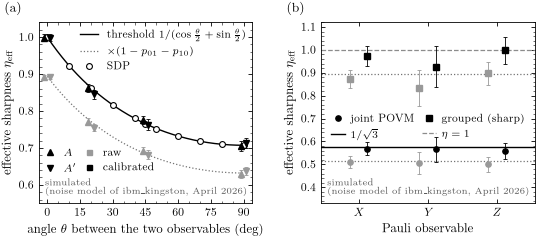

In [9]:
usetex = setup(find_latex())
fig = noisy_sim_figure(Q72, json.loads((RESULTS / "sdp_eta.json").read_text()), cal_mode="cal_asym",
                       label="simulated|(noise model of ibm_kingston, April 2026)", usetex=usetex)
fig.savefig(FIGURES / "fig_noisy_sim.pdf"); fig.savefig(FIGURES / "fig_noisy_sim.png", dpi=300)
plt.show()

## Comparison with the numbers printed in the paper

`reference/appendix_tables.json` contains the rows of Tables 2 and 3 as printed in the paper.

In [10]:
ref = json.loads((REFERENCE / "appendix_tables.json").read_text())
for name, rows, key in (("Table 2", tex2, "table2_tomographic_sharpness_qubit72"), ("Table 3", tex3, "table3_asymmetric_readout")):
    hits = [a == b for a, b in zip(rows, ref[key])]
    print(f"{name}: {sum(hits)}/{len(rows)} rows identical to the paper")

Table 2: 4/4 rows identical to the paper
Table 3: 4/4 rows identical to the paper
